# E-commerce 360 | Priorización operativa de órdenes

**Caso integrador — Analytics Essentials I · Análisis operativo en Python**  
**Área de aplicación:** Operaciones y Servicio al Cliente  
**Fuente principal:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), integrada y preparada en R.

## De la evidencia a la decisión

El diagnóstico exploratorio identificó diferencias de experiencia por región y categoría y una asociación relevante entre **retrasos logísticos** y **calificaciones bajas**. El siguiente paso es convertir esas señales en una regla de revisión **consistente, reproducible y explicable**.

**Pregunta central:** ¿Qué órdenes deberían recibir atención prioritaria considerando su desempeño logístico, la satisfacción del cliente y su valor comercial?

Este notebook resuelve la pregunta operativa: **¿cómo clasificar cada orden en Alta, Media o Baja y qué acción correspondería?**

El resultado es una `cola_priorizada.csv` con orden, indicadores, puntaje, motivos y acción recomendada. La clasificación constituye una **simulación retrospectiva**, no un modelo predictivo ni una alerta de pedidos activos.


## Alcance y secuencia de análisis

La historia sigue cinco etapas: **validar la vista 360 → definir la política → asignar prioridades → dimensionar el alcance → proponer acciones**.

- **Unidad de análisis:** una fila por `order_id`, preservada desde R.
- **Cohorte:** órdenes entregadas compradas entre enero de 2017 y agosto de 2018.
- **Experiencia:** promedio de reseñas por orden; una orden sin reseña no es considerada satisfecha.
- **Exposición comercial:** `valor_productos` (R$), diferente de margen, utilidad o pérdida.
- **Regla de atención:** puntuación transparente basada en retraso, calificación y valor; pesos definidos como una política ilustrativa, no inferidos estadísticamente.
- **Contexto adicional:** categoría, región y flete no agregan puntos automáticamente. La inflación anual de Brasil se incorpora por API a un resumen agregado, sin intervenir en las prioridades.

Las salidas se guardan en `salidas/operativo_python/`, y la entrada es `vista_ordenes_python.csv`, generada por el notebook de R.


## 0. Entorno y parámetros de clasificación

Centralizamos rutas, umbrales y parámetros para que el cálculo sea reproducible. Los pesos reflejan una **política de atención explícita**: son decisiones de negocio que pueden auditarse y contrastarse con la capacidad operativa.


In [5]:
from dataclasses import dataclass
from datetime import datetime, timezone
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.3f}".format)

# Opcional: indicar la ubicación exacta del CSV exportado desde R.
RUTA_CSV_MANUAL = ""

RAIZ = Path("..") if Path.cwd().name == "notebooks" else Path(".")
RUTA_SALIDA = RAIZ / "salidas" / "operativo_python"
RUTA_SALIDA.mkdir(parents=True, exist_ok=True)

# Política inicial: umbrales explícitos y revisables, motivados por el diagnóstico de R.
UMBRAL_RETRASO_IMPORTANTE = 4      # Días calendario: inicio del tramo de 4–7 días explorado en R.
UMBRAL_CALIFICACION_BAJA = 2       # Promedio de reseñas por orden, escala 1–5.
CUANTIL_VALOR_ALTO = 0.75          # Q4 de valor de productos, calculado en la cohorte.
PUNTOS_ALTA = 3                   # 3–5 Alta, 1–2 Media, 0 Baja.

COLORES = {"Alta": "#BB5B49", "Media": "#D18A3D", "Baja": "#287D8E"}
ORDEN_PRIORIDAD = ["Alta", "Media", "Baja"]

## 1. Verificar la base sobre la que tomaremos decisiones

La vista de R reúne identificadores, logística, satisfacción y valor comercial. Antes de clasificar órdenes, confirmamos la condición indispensable del caso: **una única fila por `order_id`**.

También comprobamos que el retraso no sea negativo, que el valor de los productos sea válido y que los indicadores lógicos coincidan con sus variables de origen. Reportamos explícitamente cuántas órdenes tienen reseña, porque ese dato condiciona la interpretación de las prioridades.

In [6]:
ubicaciones = (
    [Path(RUTA_CSV_MANUAL)] if RUTA_CSV_MANUAL.strip() else [
        RAIZ / "salidas" / "exploratorio_r" / "vista_ordenes_python.csv",
        Path("salidas/exploratorio_r/vista_ordenes_python.csv"),
        Path("../salidas/exploratorio_r/vista_ordenes_python.csv"),
        Path("/content/vista_ordenes_python.csv"),
        Path("vista_ordenes_python.csv"),
    ]
)
ruta_entrada = next((ruta for ruta in ubicaciones if ruta.is_file()), None)
if ruta_entrada is None:
    raise FileNotFoundError(
        "Falta vista_ordenes_python.csv. Ejecuta la exportación de R o configura "
        "RUTA_CSV_MANUAL con la ruta del CSV."
    )

ordenes = pd.read_csv(
    ruta_entrada,
    dtype={"order_id": "string", "customer_id": "string"},
    parse_dates=["fecha_compra"],
    low_memory=False,
)

requeridas = {
    "order_id", "fecha_compra", "categoria_orden", "region",
    "valor_productos", "flete", "flete_relativo", "dias_retraso",
    "satisfaccion", "calificacion_baja", "entrega_tardia",
}
faltantes = requeridas.difference(ordenes.columns)
if faltantes:
    raise ValueError(f"La vista de R no contiene las columnas requeridas: {sorted(faltantes)}")
if ordenes["order_id"].isna().any() or ordenes["order_id"].duplicated().any():
    raise ValueError("La vista no cumple la regla de una fila por order_id.")

numericas = ["valor_productos", "flete", "flete_relativo", "dias_retraso", "satisfaccion"]
ordenes[numericas] = ordenes[numericas].apply(pd.to_numeric, errors="coerce")
if (ordenes["valor_productos"].isna() | (ordenes["valor_productos"] <= 0)).any():
    raise ValueError("Se encontraron importes de productos ausentes o no positivos.")
if (ordenes["dias_retraso"].isna() | (ordenes["dias_retraso"] < 0)).any():
    raise ValueError("dias_retraso debe ser numérico, válido y no negativo.")
if ordenes["fecha_compra"].isna().any():
    raise ValueError("La vista contiene fechas de compra no interpretables.")
if not ordenes["satisfaccion"].dropna().between(1, 5).all():
    raise ValueError("La calificación debe encontrarse entre 1 y 5.")

# Auditoría de coherencia con las variables booleanas exportadas desde R.
def leer_logico(serie):
    return serie.astype("string").str.strip().str.lower().map({
        "true": True, "false": False, "1": True, "0": False,
    }).astype("boolean")

if not leer_logico(ordenes["entrega_tardia"]).eq(ordenes["dias_retraso"].gt(0)).fillna(False).all():
    raise ValueError("entrega_tardia no coincide con dias_retraso > 0.")

baja_r = leer_logico(ordenes["calificacion_baja"])
baja_calculada = ordenes["satisfaccion"].le(UMBRAL_CALIFICACION_BAJA).where(
    ordenes["satisfaccion"].notna(), pd.NA
).astype("boolean")
if (baja_r.isna() != baja_calculada.isna()).any() or not baja_r.eq(baja_calculada).fillna(True).all():
    raise ValueError("calificacion_baja no coincide con la calificación de R.")

control = pd.Series({
    "Órdenes": len(ordenes),
    "Order_id únicos": ordenes["order_id"].nunique(),
    "Sin reseña": ordenes["satisfaccion"].isna().sum(),
    "Con reseña": ordenes["satisfaccion"].notna().sum(),
    "Inicio de compras": ordenes["fecha_compra"].min().date(),
    "Fin de compras": ordenes["fecha_compra"].max().date(),
}, name="Control de entrada")
display(control.to_frame())
print("CSV de entrada:", ruta_entrada)

,Control de entrada
Órdenes,96203
Order_id únicos,96203
Sin reseña,643
Con reseña,95560
Inicio de compras,2017-01-05
Fin de compras,2018-08-29


CSV de entrada: ..\salidas\exploratorio_r\vista_ordenes_python.csv


**Control de la base.** La vista contiene **96.203 órdenes únicas**, de las cuales **95.560** cuentan con una calificación utilizable y **643** no tienen reseña. Esta cobertura delimita qué órdenes pueden activar la señal de satisfacción negativa.

Al conservar los faltantes como ausencia de información, evitamos confundir no respuesta con buena experiencia. Sobre esta base consistente aplicamos las reglas de clasificación.


## 2. Diseñar una política transparente de atención

El diagnóstico en R sugiere estudiar el retraso como señal logística; las calificaciones bajas representan una evidencia histórica directa de mala experiencia y el valor de los productos permite dimensionar exposición comercial. **Estos criterios no se traducen automáticamente en pesos:** aquí proponemos una política de revisión que pueda explicarse y auditarse.

| Señal observable | Criterio propuesto | Puntos |
|---|---|---:|
| Calificación baja | `satisfaccion ≤ 2`, cuando exista reseña | 2 |
| Retraso importante | `dias_retraso ≥ 4` días calendario | 2 |
| Retraso corto | `0 < dias_retraso < 4` | 1 |
| Valor comercial alto | `valor_productos ≥ percentil 75` de la cohorte | 1 |

**Puntaje total = calificación + retraso + valor** (0 a 5). Se asigna prioridad **Alta (3–5)**, **Media (1–2)** o **Baja (0)**.

Dos restricciones de interpretación:

- El **flete relativo** queda como variable de contexto, pero no recibe puntos: no hemos establecido un umbral ni una justificación operativa suficientemente sólida para su ponderación.
- Ni la **región** ni la **categoría** suman puntos por sí mismas. Sus diferencias descriptivas ayudan a entender los resultados, pero no deberían penalizar automáticamente a todas las órdenes de un segmento.

Las prioridades muestran dónde concentraría la revisión **esta regla propuesta**, no una probabilidad de insatisfacción futura.

In [7]:
# Pesos de los indicadores de priorización
PESO_CALIFICACION_BAJA = 2
PESO_RETRASO_IMPORTANTE = 2
PESO_RETRASO_CORTO = 1
PESO_VALOR_ALTO = 1

In [8]:
umbral_valor = float(ordenes["valor_productos"].quantile(CUANTIL_VALOR_ALTO))

# Construcción de señales
alertas = ordenes.copy()

alertas["sin_resena"] = alertas["satisfaccion"].isna()
alertas["senal_calificacion_baja"] = alertas["satisfaccion"].le(UMBRAL_CALIFICACION_BAJA)
alertas["senal_retraso_importante"] = alertas["dias_retraso"].ge(UMBRAL_RETRASO_IMPORTANTE)
alertas["senal_retraso_corto"] = alertas["dias_retraso"].gt(0) & ~alertas["senal_retraso_importante"]
alertas["senal_valor_alto"] = alertas["valor_productos"].ge(umbral_valor)

# Asignación de puntos según los pesos definidos
alertas["puntos_calificacion"] = (
    alertas["senal_calificacion_baja"].astype(int) * PESO_CALIFICACION_BAJA
)

alertas["puntos_retraso"] = np.select(
    [alertas["senal_retraso_importante"], alertas["senal_retraso_corto"]],
    [PESO_RETRASO_IMPORTANTE, PESO_RETRASO_CORTO],
    default=0,
)

alertas["puntos_valor"] = (
    alertas["senal_valor_alto"].astype(int) * PESO_VALOR_ALTO
)

# Puntaje total
alertas["puntaje"] = alertas[
    ["puntos_calificacion", "puntos_retraso", "puntos_valor"]
].sum(axis=1).astype(int)

# Clasificación de prioridades
alertas["prioridad"] = pd.Categorical(
    np.select(
        [alertas["puntaje"].ge(PUNTOS_ALTA), alertas["puntaje"].gt(0)],
        ["Alta", "Media"],
        default="Baja",
    ),
    categories=ORDEN_PRIORIDAD,
    ordered=True,
)

print(f"Umbral de valor alto (P75): R$ {umbral_valor:,.2f}")
print("Distribución inicial de prioridades:")
display(alertas["prioridad"].value_counts(sort=False).rename("Órdenes").to_frame())

Umbral de valor alto (P75): R$ 149.90
Distribución inicial de prioridades:


,Órdenes
prioridad,
Alta,6926
Media,27928
Baja,61349


### 2.1. Convertir el puntaje en motivos y acciones

Una prioridad tiene utilidad operativa cuando es posible explicar **qué condiciones la activaron**. La función `construir_motivos()` describe las señales de cada orden y la clase `AlertaOrden` permite contrastar la clasificación individual con el cálculo vectorizado.

La recomendación depende del nivel y del tipo de señal observada: atención postventa, revisión logística, seguimiento comercial o monitoreo agregado. Las acciones ilustran una política de revisión histórica, sin atribuirles una mejora causal de la satisfacción.


In [9]:
def construir_motivos(datos: pd.DataFrame) -> pd.Series:
    """Devuelve factores activados, sin confundir ausencia de reseña con buena nota."""
    motivos = pd.Series("", index=datos.index, dtype="string")
    condiciones = (
        ("senal_calificacion_baja", "Calificación ≤2"),
        ("senal_retraso_importante", "Retraso ≥4 días"),
        ("senal_retraso_corto", "Retraso 1–3 días"),
        ("senal_valor_alto", "Valor alto (P75)"),
    )
    for columna, texto in condiciones:
        motivos = motivos + np.where(datos[columna], texto + "; ", "")
    return motivos.str.rstrip("; ").replace("", "Sin señales de alerta")


@dataclass(frozen=True)
class AlertaOrden:
    order_id: str
    puntaje: int

    def nivel(self) -> str:
        if self.puntaje >= PUNTOS_ALTA:
            return "Alta"
        if self.puntaje > 0:
            return "Media"
        return "Baja"


alertas["factores_activados"] = construir_motivos(alertas)

# Acciones diferenciadas según prioridad y causa observada (simulación histórica).
condiciones_accion = [
    alertas["prioridad"].eq("Alta") & alertas["senal_calificacion_baja"],
    alertas["prioridad"].eq("Alta") & alertas["senal_retraso_importante"],
    alertas["prioridad"].eq("Alta"),
    alertas["prioridad"].eq("Media") & alertas["senal_calificacion_baja"],
    alertas["prioridad"].eq("Media") & alertas["dias_retraso"].gt(0),
    alertas["prioridad"].eq("Media"),
]
acciones = [
    "Revisar atención postventa; evaluar contacto o compensación",
    "Auditar retraso logístico; evaluar escalamiento",
    "Revisión individual de señales concurrentes",
    "Revisar insatisfacción registrada",
    "Verificar cumplimiento logístico",
    "Seguimiento comercial preventivo",
]
alertas["accion_sugerida"] = np.select(
    condiciones_accion, acciones, default="Monitoreo agregado periódico"
)

# La clase reproduce la decisión vectorizada en una muestra de comprobación.
muestra = alertas[["order_id", "puntaje", "prioridad"]].head(30)
comprobacion = muestra.apply(
    lambda fila: AlertaOrden(fila["order_id"], int(fila["puntaje"])).nivel(),
    axis=1,
)
assert (comprobacion.to_numpy() == muestra["prioridad"].astype(str).to_numpy()).all()
assert alertas["puntaje"].between(0, 5).all()
assert alertas["factores_activados"].notna().all()

columnas_ejemplo = [
    "order_id", "dias_retraso", "satisfaccion", "valor_productos",
    "puntaje", "prioridad", "factores_activados", "accion_sugerida",
]
display(alertas.sort_values(["puntaje", "valor_productos"], ascending=False)[columnas_ejemplo].head(8))

,order_id,dias_retraso,satisfaccion,valor_productos,puntaje,prioridad,factores_activados,accion_sugerida
92908,d7a2c0c1ff66b314f3bf166fb4157fd4,23,2.000,2990.000,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...
392,da8be3bb62e9bf01e2e1a3bfd74ebd1a,4,1.000,2690.000,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...
47100,bf205457ee84ab84c423d67b88239982,9,1.000,2649.990,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...
94742,a5d11ae16578088b0fcd76de30368bdb,16,1.000,2433.600,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...
21238,6d0940a8f5fba47562bb14cd97dfd6da,15,1.000,2350.000,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...
91626,e81fbdf6c9bbdc3b6a9cd243b617e576,4,1.000,2199.000,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...
31081,773f048245dc975a5f7c67c2415c88a0,96,1.000,2029.000,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...
6437,dc03cba6a1d6cf5c28d1fde5dab9a0bd,9,1.000,1999.990,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...


**Resultado operativo.** Cada orden queda asociada con un **puntaje**, una **prioridad**, los **factores activados** y una **acción sugerida**. Los ejemplos mostrados permiten examinar las combinaciones de señales que concentran mayor atención.

Una vez construida la clasificación, evaluamos su alcance en número de órdenes y en valor de productos para dimensionar la carga que implicaría esa política.


## 3. ¿Qué tan amplia es la cola priorizada?

Para evaluar si la política resulta operativamente razonable calculamos dos distribuciones: proporción de **órdenes** y participación en **valor de productos**. También medimos la tasa de prioridad Alta por región y categoría, conectándola con el diagnóstico exploratorio.

Utilizamos `groupby().agg()`, `pivot_table()` y una unión validada con `merge(validate="one_to_one")`. Los cruces por segmento describen el resultado de la política; **no cambian los puntajes de las órdenes**.

In [10]:
resumen_prioridades = (
    alertas.groupby("prioridad", observed=True)
    .agg(
        ordenes=("order_id", "size"),
        valor_productos=("valor_productos", "sum"),
        con_resena=("sin_resena", lambda x: (~x).sum()),
        demora_media=("dias_retraso", "mean"),
    )
    .reindex(ORDEN_PRIORIDAD, fill_value=0)
    .reset_index()
)
resumen_prioridades["pct_ordenes"] = (
    resumen_prioridades["ordenes"] / resumen_prioridades["ordenes"].sum()
)
resumen_prioridades["pct_valor"] = (
    resumen_prioridades["valor_productos"] / resumen_prioridades["valor_productos"].sum()
)
assert resumen_prioridades["ordenes"].sum() == len(alertas)
assert np.isclose(resumen_prioridades["pct_valor"].sum(), 1.0)
display(resumen_prioridades)

resumen_regional = (
    alertas.groupby("region", dropna=False)
    .agg(ordenes=("order_id", "size"),
         prioridad_alta=("prioridad", lambda s: s.eq("Alta").sum()),
         valor_productos=("valor_productos", "sum"))
    .reset_index()
)
resumen_regional["tasa_alta"] = (
    resumen_regional["prioridad_alta"] / resumen_regional["ordenes"]
)

matriz_regional = (
    alertas.pivot_table(
        index="region", columns="prioridad", values="order_id",
        aggfunc="count", fill_value=0, observed=True,
    )
    .reindex(columns=ORDEN_PRIORIDAD, fill_value=0)
    .add_prefix("ordenes_")
    .reset_index()
)
resumen_regional = resumen_regional.merge(
    matriz_regional, on="region", how="left", validate="one_to_one"
)
assert (resumen_regional["ordenes"] == resumen_regional[
    [f"ordenes_{p}" for p in ORDEN_PRIORIDAD]
].sum(axis=1)).all()

resumen_categorias_operativo = (
    alertas.groupby("categoria_orden", dropna=False)
    .agg(ordenes=("order_id", "size"),
         prioridad_alta=("prioridad", lambda s: s.eq("Alta").sum()))
    .reset_index()
)
resumen_categorias_operativo["tasa_alta"] = (
    resumen_categorias_operativo["prioridad_alta"] /
    resumen_categorias_operativo["ordenes"]
)

print("Prioridad alta por región:")
display(resumen_regional.sort_values("tasa_alta", ascending=False))
print("Categorías con más órdenes de prioridad alta (mínimo 500 órdenes):")
display(
    resumen_categorias_operativo.query("ordenes >= 500")
    .nlargest(8, "prioridad_alta")
)

,prioridad,ordenes,valor_productos,con_resena,demora_media,pct_ordenes,pct_valor
0,Alta,6926,1682561.950,6874,7.848,0.072,0.128
1,Media,27928,7327863.230,27683,0.536,0.290,0.556
2,Baja,61349,4169352.770,61003,0.000,0.638,0.316


Prioridad alta por región:


,region,ordenes,prioridad_alta,valor_productos,tasa_alta,ordenes_Alta,ordenes_Media,ordenes_Baja
1,Nordeste,9015,1089,1491911.330,0.121,1089,3058,4868
2,Norte,1791,193,325947.650,0.108,193,636,962
0,Centro-Oeste,5610,420,844960.640,0.075,420,1744,3446
4,Sur,13767,915,1895016.990,0.066,915,3963,8889
3,Sudeste,66020,4309,8621941.340,0.065,4309,18527,43184


Categorías con más órdenes de prioridad alta (mínimo 500 órdenes):


,categoria_orden,ordenes,prioridad_alta,tasa_alta
7,bed_bath_table,9202,752,0.082
43,health_beauty,8577,600,0.070
15,computers_accessories,6500,499,0.077
68,sports_leisure,7474,497,0.066
73,watches_gifts,5471,491,0.090
39,furniture_decor,6142,490,0.080
49,housewares,5671,329,0.058
5,auto,3783,299,0.079


### 3.1. Figura P01 — Distribución de órdenes y valor comercial

La primera barra muestra la proporción de órdenes asignadas a cada nivel; la segunda, la proporción de su valor comercial. Ambas suman 100% en su propia dimensión.

El contraste permite evaluar si la regla concentra la atención en pocos pedidos o en una fracción amplia del negocio. Debe leerse con cautela: **el valor comercial ya participa en el puntaje**, por lo que parte de la mayor concentración de valor en niveles superiores es una consecuencia de la propia regla.

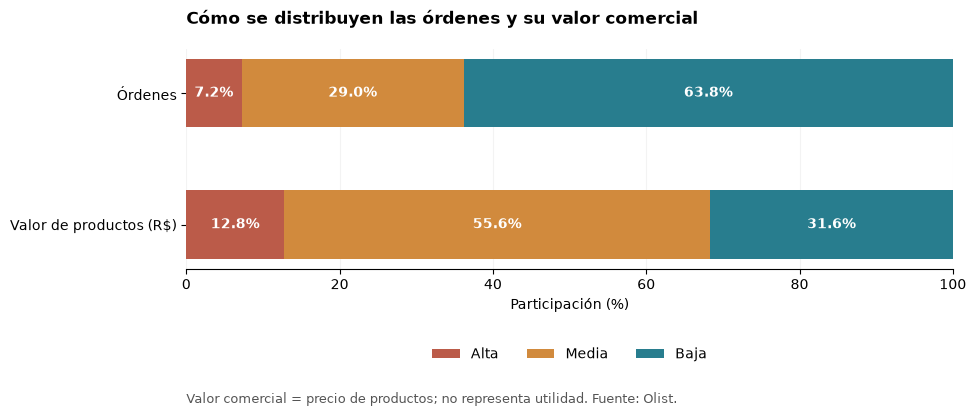

In [11]:
fig, ax = plt.subplots(figsize=(10.5, 4.4))
filas = ["Órdenes", "Valor de productos (R$)"]
y = np.arange(len(filas))
izquierda = np.zeros(2)

for prioridad in ORDEN_PRIORIDAD:
    fila = resumen_prioridades.set_index("prioridad").loc[prioridad]
    porcentajes = np.array([fila["pct_ordenes"], fila["pct_valor"]]) * 100
    ax.barh(y, porcentajes, left=izquierda, color=COLORES[prioridad],
            height=0.52, label=prioridad)
    for posicion, porcentaje, inicio in zip(y, porcentajes, izquierda):
        if porcentaje >= 5:
            ax.text(inicio + porcentaje / 2, posicion, f"{porcentaje:.1f}%",
                    ha="center", va="center", color="white", fontweight="bold")
    izquierda += porcentajes

ax.set_yticks(y, filas)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Participación (%)")
ax.set_title("Cómo se distribuyen las órdenes y su valor comercial",
             fontweight="bold", loc="left", pad=18)
ax.legend(ncol=3, frameon=False,
          loc="upper center", bbox_to_anchor=(0.5, -0.30))
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
fig.subplots_adjust(left=0.25, right=0.98, top=0.84, bottom=0.34)
fig.text(0.25, 0.035, "Valor comercial = precio de productos; no representa utilidad. Fuente: Olist.",
         fontsize=9, color="#555555")
fig.savefig(RUTA_SALIDA / "P01_distribucion_prioridades.png", dpi=190, bbox_inches="tight")
plt.show()

**Hallazgo.** La prioridad **Alta** agrupa **7,2 %** de las órdenes y **12,8 %** del valor de productos. En conjunto, **Alta + Media** representan **36,2 %** de las órdenes, pero concentran **68,4 %** del valor comercial observado. La prioridad **Media**, por sí sola, reúne **55,6 %** del valor de productos.

**Lectura de negocio.** La regla delimita distintos niveles de revisión y revela que el seguimiento de prioridad Media también comprende una parte importante del valor comercial. Sin embargo, **el valor ya participa en el puntaje**: la concentración observada es parcialmente consecuencia del diseño de la política y no una estimación de pérdidas evitables.


## 4. ¿Qué señales activan las prioridades más altas?

Una vez dimensionado el conjunto Alta, necesitamos comprender **por qué** se clasificó así. Contamos las órdenes Alta que activaron cada señal: calificación baja, retraso importante, retraso corto y valor alto.

**Una misma orden puede activar varias señales.** Por tanto, los recuentos del gráfico son superpuestos y **no deben sumarse** como si representaran grupos excluyentes. Este gráfico describe la composición de nuestra regla, **no identifica causas del descontento**.

### 4.1. Figura P02 — Factores presentes en órdenes de prioridad Alta

Las barras muestran cuántas órdenes Alta cumplen cada condición. La señal predominante permite orientar qué tipo de revisión sería más habitual bajo la política propuesta (por ejemplo, logística o atención postventa).

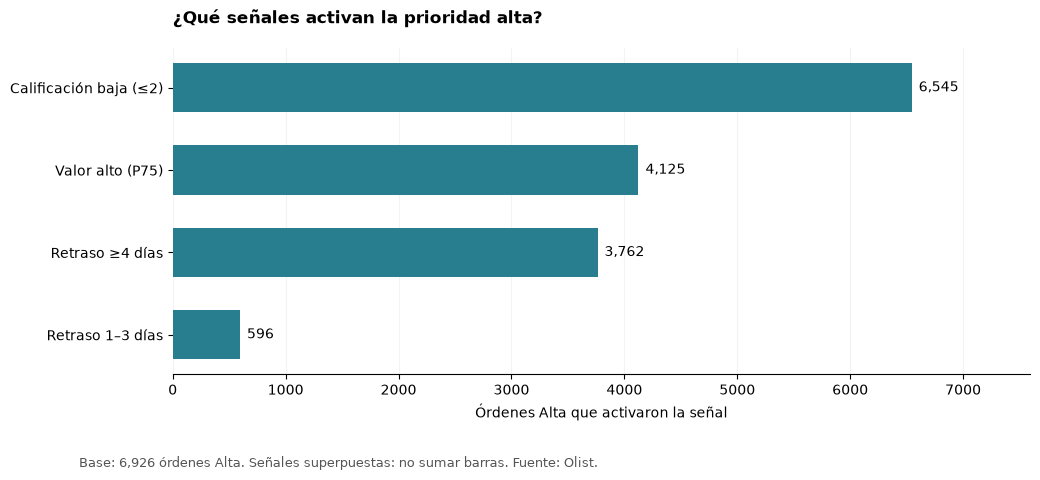

In [12]:
altas = alertas.loc[alertas["prioridad"].eq("Alta")].copy()

factores_alta = pd.Series({
    "Calificación baja (≤2)": int(altas["senal_calificacion_baja"].sum()),
    "Retraso ≥4 días": int(altas["senal_retraso_importante"].sum()),
    "Retraso 1–3 días": int(altas["senal_retraso_corto"].sum()),
    "Valor alto (P75)": int(altas["senal_valor_alto"].sum()),
}, name="ordenes_activadas").sort_values()

fig, ax = plt.subplots(figsize=(10.5, 4.8))
barras = ax.barh(factores_alta.index, factores_alta.values, color="#287D8E", height=0.60)
ax.bar_label(barras, padding=5, fmt="{:,.0f}")
ax.set_xlim(0, max(1, factores_alta.max()) * 1.16)
ax.set_xlabel("Órdenes Alta que activaron la señal")
ax.set_title("¿Qué señales activan la prioridad alta?", fontweight="bold", loc="left", pad=18)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
fig.text(0.08, 0.015,
         f"Base: {len(altas):,} órdenes Alta. Señales superpuestas: no sumar barras. Fuente: Olist.",
         fontsize=9, color="#555555")
fig.tight_layout(rect=[0, 0.08, 1, 1])
fig.savefig(RUTA_SALIDA / "P02_factores_prioridad_alta.png", dpi=190, bbox_inches="tight")
plt.show()

**Hallazgo.** Entre las órdenes clasificadas como Alta, la señal más frecuente es **calificación baja (≤ 2)**, presente en **6.545 órdenes**. Los factores pueden coexistir dentro de una misma orden y, por ello, sus conteos no deben sumarse.

**Lectura de negocio.** La elevada presencia de reseñas desfavorables orienta una revisión de **postventa y experiencia del cliente**. Las señales logísticas permiten identificar dónde conviene examinar incumplimientos de entrega. El gráfico describe las condiciones que activa la regla; no determina las causas de la insatisfacción.


## 5. Síntesis ejecutiva y propuesta de atención

La distribución de prioridades dimensiona la **carga potencial de revisión** y el gráfico de factores muestra **por qué se activan las alertas**. Reunimos los indicadores centrales en una tabla trazable y los vinculamos con acciones diferenciadas.

| Prioridad | Interpretación dentro de la política | Acción sugerida |
|---|---|---|
| **Alta** | Señales concurrentes o intensidad suficiente para superar el umbral | Revisión individual, análisis postventa/logístico y eventual escalamiento |
| **Media** | Señales relevantes, pero sin alcanzar la puntuación Alta | Seguimiento focalizado y revisión preventiva del servicio |
| **Baja** | Sin señales puntuadas bajo esta política | Monitoreo agregado de calidad |

Estos niveles expresan una política de gestión histórica; no estiman probabilidades de reclamo o pérdidas futuras.


In [13]:
# Indicadores de la política y resultados de la clasificación.
resumen_idx = resumen_prioridades.set_index("prioridad")
altas_pct = float(resumen_idx.loc["Alta", "pct_ordenes"])
altas_valor_pct = float(resumen_idx.loc["Alta", "pct_valor"])
alta_media_pct = float(resumen_idx.loc[["Alta", "Media"], "pct_ordenes"].sum())
alta_media_valor_pct = float(resumen_idx.loc[["Alta", "Media"], "pct_valor"].sum())

factor_principal = (
    factores_alta.idxmax() if len(altas) > 0 else "Sin órdenes Alta"
)
factor_principal_n = int(factores_alta.max()) if len(altas) > 0 else 0
regiones_validas = resumen_regional.loc[
    resumen_regional["region"].notna() &
    resumen_regional["region"].ne("Sin región")
]
region_alta = (
    regiones_validas.loc[regiones_validas["tasa_alta"].idxmax(), "region"]
    if not regiones_validas.empty else "s/d"
)

resumen_para_conclusiones = pd.DataFrame({
    "indicador": [
        "Órdenes clasificadas", "Órdenes sin reseña", "Umbral de valor (P75)",
        "Prioridad Alta: participación en órdenes",
        "Prioridad Alta: participación en valor",
        "Alta + Media: participación en órdenes",
        "Alta + Media: participación en valor",
        "Señal predominante en Alta", "Órdenes Alta con esa señal",
        "Región con mayor tasa de prioridad Alta",
    ],
    "resultado": [
        f"{len(alertas):,}", f"{alertas['sin_resena'].sum():,}",
        f"R$ {umbral_valor:,.2f}", f"{altas_pct:.1%}",
        f"{altas_valor_pct:.1%}", f"{alta_media_pct:.1%}",
        f"{alta_media_valor_pct:.1%}", factor_principal,
        f"{factor_principal_n:,}", str(region_alta),
    ],
})
display(resumen_para_conclusiones)

,indicador,resultado
0,Órdenes clasificadas,"96,203"
1,Órdenes sin reseña,643
2,Umbral de valor (P75),R$ 149.90
3,Prioridad Alta: participación en órdenes,7.2%
4,Prioridad Alta: participación en valor,12.8%
5,Alta + Media: participación en órdenes,36.2%
6,Alta + Media: participación en valor,68.4%
7,Señal predominante en Alta,Calificación baja (≤2)
8,Órdenes Alta con esa señal,"6,545"
9,Región con mayor tasa de prioridad Alta,Nordeste


### Conclusiones y respuesta a la pregunta de negocio

1. **Alcance de la priorización.** La política clasifica **6.926 órdenes** (**7,2 %**) como prioridad Alta; representan **12,8 %** del valor de productos. La combinación de Alta y Media concentra **68,4 %** del valor comercial en **36,2 %** de las órdenes.
2. **Naturaleza de las alertas.** Entre las órdenes Alta, **6.545** presentan calificación baja. La concentración de esta señal sugiere orientar la revisión individual hacia problemas de experiencia y postventa, complementándola con el seguimiento logístico cuando existen demoras.
3. **Segmentación operativa.** **Nordeste** registra la mayor proporción regional de órdenes clasificadas como Alta (**12,1 %**). Esta distribución permite examinar dónde se concentra la carga relativa de la política, sin penalizar a las órdenes únicamente por su localización.

**Respuesta.** Las órdenes que encabezan la `cola_priorizada.csv` son las que reúnen más señales según una regla explícita de **satisfacción, retraso y valor comercial**. Cada caso tiene un puntaje, los motivos que sustentan su posición y una acción sugerida. La clasificación es una propuesta de **triage retrospectivo** y no prueba la efectividad de las intervenciones.


## 6. Integración de contexto macroeconómico

Se consulta la [API pública del Banco Mundial — inflación anual de Brasil (FP.CPI.TOTL.ZG)](https://api.worldbank.org/v2/country/BRA/indicator/FP.CPI.TOTL.ZG?format=json). La respuesta se registra con su URL y fecha UTC, y se vincula mediante el **año de compra** con una tabla agregada de órdenes y valor de productos.

La inflación aporta **contexto anual**; no se utiliza para puntuar órdenes, ni una coincidencia de años implica causalidad sobre satisfacción o logística.


In [14]:
URL_BM = "https://api.worldbank.org/v2/country/BRA/indicator/FP.CPI.TOTL.ZG"
consulta_utc = datetime.now(timezone.utc).isoformat(timespec="seconds")
anios = ordenes["fecha_compra"].dt.year
anio_min, anio_max = int(anios.min()), int(anios.max())
parametros = {"format": "json", "per_page": 100, "date": f"{anio_min}:{anio_max}"}

# Tabla anual: no une contexto macroeconómico a filas individuales para puntuar.
resumen_anual = (
    alertas.assign(anio_compra=alertas["fecha_compra"].dt.year)
    .groupby("anio_compra", as_index=False)
    .agg(ordenes=("order_id", "size"), valor_productos=("valor_productos", "sum"))
)

inflacion = pd.DataFrame({
    "anio_compra": pd.Series(dtype="int64"),
    "inflacion_brasil_pct": pd.Series(dtype="float64"),
})
estado_api = "Sin datos de la API"
url_consulta = requests.Request("GET", URL_BM, params=parametros).prepare().url

try:
    respuesta = requests.get(URL_BM, params=parametros, timeout=20)
    respuesta.raise_for_status()
    contenido = respuesta.json()
    if not isinstance(contenido, list) or len(contenido) < 2 or not isinstance(contenido[1], list):
        raise ValueError("La API no devolvió una lista de registros válida.")
    registros = [
        {"anio_compra": int(item["date"]), "inflacion_brasil_pct": item["value"]}
        for item in contenido[1]
        if item.get("date") and item.get("value") is not None
    ]
    inflacion = pd.DataFrame(registros, columns=["anio_compra", "inflacion_brasil_pct"])
    if inflacion["anio_compra"].duplicated().any():
        raise ValueError("La API devolvió más de un registro por año.")
    inflacion["inflacion_brasil_pct"] = pd.to_numeric(
        inflacion["inflacion_brasil_pct"], errors="coerce"
    )
    (RUTA_SALIDA / "respuesta_api_banco_mundial.json").write_text(
        json.dumps(contenido, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    estado_api = "Consulta exitosa" if not inflacion.empty else "Consulta sin años disponibles"
except (requests.RequestException, ValueError, KeyError, TypeError) as exc:
    estado_api = f"Consulta no completada: {type(exc).__name__}: {exc}"
    print("Aviso:", estado_api)

contexto_anual = resumen_anual.merge(
    inflacion, on="anio_compra", how="left", validate="one_to_one"
)
registro_api = pd.DataFrame([{
    "fuente": "Banco Mundial - inflación anual Brasil",
    "url": url_consulta,
    "consulta_utc": consulta_utc,
    "estado": estado_api,
    "llave_union": "anio_compra (año)",
    "uso": "Contexto anual; no afecta puntaje ni prioridad",
}])
print("Estado de la integración web:", estado_api)
display(contexto_anual)

Estado de la integración web: Consulta exitosa


,anio_compra,ordenes,valor_productos,inflacion_brasil_pct
0,2017,43426,5962605.710,3.446
1,2018,52777,7217172.240,3.665


## 7. Productos del análisis operativo

La **cola priorizada** constituye el producto central del notebook. Su ordenamiento combina nivel de prioridad, puntaje y valor de productos, y conserva los indicadores que explican cada asignación.

| Archivo | Contenido |
|---|---|
| `cola_priorizada.csv` | Órdenes con puntaje, prioridad, factores y acción sugerida |
| `resumen_prioridades.csv` | Participación de órdenes y valor por prioridad |
| `resumen_prioridad_regiones.csv`, `resumen_prioridad_categorias.csv` | Distribución operativa por segmento |
| `factores_prioridad_alta.csv` | Señales concurrentes entre órdenes de prioridad Alta |
| `resumen_para_conclusiones_python.csv` | Indicadores consolidados del resultado |
| `contexto_brasil_anual.csv`, `registro_api.csv` | Integración anual y trazabilidad de la fuente web |
| `P01_distribucion_prioridades.png`, `P02_factores_prioridad_alta.png` | Visualizaciones del producto de priorización |

Los archivos se generan en `salidas/operativo_python/`. Las tablas permiten auditar los hallazgos y reproducir los gráficos.


In [15]:
# Orden estable para la cola: mayor prioridad, puntaje y valor comercial.
cola_priorizada = (
    alertas.sort_values(
        ["prioridad", "puntaje", "valor_productos", "order_id"],
        ascending=[True, False, False, True]
    )[[
        "order_id", "customer_id", "fecha_compra", "categoria_orden", "region",
        "valor_productos", "flete", "flete_relativo", "dias_retraso",
        "satisfaccion", "sin_resena", "senal_calificacion_baja",
        "senal_retraso_importante", "senal_retraso_corto", "senal_valor_alto",
        "puntos_calificacion", "puntos_retraso", "puntos_valor",
        "puntaje", "prioridad", "factores_activados", "accion_sugerida",
    ]].reset_index(drop=True)
)

archivos_csv = {
    "cola_priorizada": cola_priorizada,
    "resumen_prioridades": resumen_prioridades,
    "resumen_para_conclusiones_python": resumen_para_conclusiones,
    "resumen_prioridad_regiones": resumen_regional,
    "resumen_prioridad_categorias": resumen_categorias_operativo,
    "factores_prioridad_alta": factores_alta.rename_axis("factor").reset_index(),
    "contexto_brasil_anual": contexto_anual,
    "registro_api": registro_api,
}
for nombre, datos in archivos_csv.items():
    datos.to_csv(RUTA_SALIDA / f"{nombre}.csv", index=False, encoding="utf-8-sig")

assert len(cola_priorizada) == len(ordenes)
assert cola_priorizada["order_id"].is_unique
assert cola_priorizada["accion_sugerida"].notna().all()

print(f"Resultados guardados en: {RUTA_SALIDA.resolve()}")
print(f"CSV: {len(archivos_csv)} · Gráficos: 2")
print("Primeras 5 órdenes priorizadas:")
display(cola_priorizada[[
    "order_id", "puntaje", "prioridad", "factores_activados", "accion_sugerida"
]].head(5))

Resultados guardados en: C:\Users\santi\OneDrive\Documents\Diploma\DataScience_Business\Analytics_Essentials_I\Caso-Integrador-Final\salidas\operativo_python
CSV: 8 · Gráficos: 2
Primeras 5 órdenes priorizadas:


,order_id,puntaje,prioridad,factores_activados,accion_sugerida
0,d7a2c0c1ff66b314f3bf166fb4157fd4,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...
1,da8be3bb62e9bf01e2e1a3bfd74ebd1a,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...
2,bf205457ee84ab84c423d67b88239982,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...
3,a5d11ae16578088b0fcd76de30368bdb,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...
4,6d0940a8f5fba47562bb14cd97dfd6da,5,Alta,Calificación ≤2; Retraso ≥4 días; Valor alto (...,Revisar atención postventa; evaluar contacto o...


## 8. Limitaciones y reproducibilidad

- **Simulación histórica:** la entrega y la reseña ya ocurrieron. La clasificación no demuestra que una intervención habría modificado las calificaciones.
- **Cobertura de reseñas:** una orden sin reseña no activa el criterio de baja satisfacción; esto puede alterar la distribución de prioridades.
- **Política explícita, no calibrada:** los puntos (2, 2, 1), el corte de cuatro días y los niveles Alta/Media/Baja son reglas transparentes; no provienen de una optimización de recursos ni de una estimación de efectividad.
- **Valor de productos:** su participación en la puntuación contribuye a la concentración comercial observada en P01. No mide margen ni pérdidas.
- **Factores superpuestos:** una misma orden puede activar varias señales, por lo que los recuentos de P02 no son categorías excluyentes.
- **Límite causal:** la exploración de R y el puntaje de Python no permiten inferir causalidad.
- **Integración web:** la inflación de Brasil se utiliza únicamente como contexto agregado anual.

**Reproducibilidad.** El notebook utiliza `pandas`, `numpy`, `matplotlib`, `requests` y la biblioteca estándar de Python. Consume la vista por orden preparada en R (`salidas/exploratorio_r/vista_ordenes_python.csv`); las rutas y los parámetros de la política están centralizados al inicio. La API pública registra URL, momento de consulta y estado de respuesta.
